In [1]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      !pip install py3Dmol
      !pip install rdkit
      pbar.update(50)
      from rdkit import Chem
      from rdkit.Chem import Descriptors, Draw, Lipinski
      from rdkit.Chem import Draw
      from rdkit.Chem.Draw import IPythonConsole
      from rdkit.Chem import AllChem # import the AllChem submodule from the Chem module
      from rdkit.Chem import rdDistGeom
      from rdkit.Chem import rdDepictor
      from IPython.display import Image
      import py3Dmol


      pbar.update(50)

  0%|          | 0/100 [00:00<?, ?it/s]

[intriducción a rdkit](https://www.rdkit.org/docs/GettingStartedInPython.html)

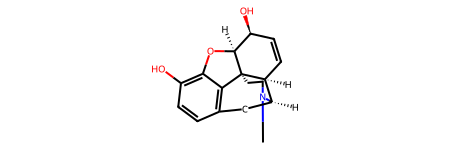

In [2]:
morphine = Chem.MolFromSmiles('CN1CC[C@]23[C@@H]4[C@H]1CC5=C2C(=C(C=C5)O)O[C@H]3[C@H](C=C4)O')
morphine

In [3]:
morphine.GetNumAtoms()

21

In [4]:
morphine.GetNumBonds()

25

In [5]:
morphine_H = Chem.AddHs(morphine)
morphine_H.GetNumAtoms()

40

In [6]:
morphine_embed = AllChem.EmbedMolecule(morphine_H)
#morphine_embed

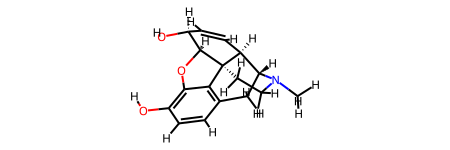

In [7]:
morphine_H

In [8]:
mw = Descriptors.MolWt(morphine)
logp = Descriptors.MolLogP(morphine)
hbd = Lipinski.NumHDonors(morphine)
hba = Lipinski.NumHAcceptors(morphine)
tpsa = Descriptors.TPSA(morphine)
rbonds = Lipinski.NumRotatableBonds(morphine)

In [9]:
print('El peso molecular es:'+ str(round(mw,2)))
print('El logP es:'+  str(round(logp,2)))
print('El número de H-bond donors es:'+ str(hbd))
print('El número de H-bond acceptors es:'+ str(hba))
print('El TPSA es:'+  str(round(tpsa,2)))
print('El número de enlaces rotatorios es:'+ str(rbonds))


El peso molecular es:285.34
El logP es:1.2
El número de H-bond donors es:2
El número de H-bond acceptors es:4
El TPSA es:52.93
El número de enlaces rotatorios es:0


#pymol

In [10]:
ps = rdDistGeom.ETDG()#ETKDG(), ETDG(), ETKDGv3()
ps.clearConfs= False
cid = rdDistGeom.EmbedMolecule(morphine_H,ps)

In [11]:
cid

1

Imprimimos el primer conformero

In [12]:
v = py3Dmol.view(width=400,height=400)
v.removeAllModels()
IPythonConsole.addMolToView(morphine_H,v,confId=0)
#v.setStyle({'model': 0, 'cartoon':{'colorscheme':'pinkCarbon'}}) # Target the second model
v.setStyle({'stick':{'colorscheme':'greenCarbon'}})
v.zoomTo()
v.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Imprimimos el segundo conformero

In [13]:
v = py3Dmol.view(width=400,height=400)
v.removeAllModels()
IPythonConsole.addMolToView(morphine_H,v,confId=1)
v.setStyle({'model': 0, 'stick':{'colorscheme':'pinkCarbon'}}) # Target the second model
#v.setStyle({'model': 0, 'line':{'colorscheme':'blackCarbon'}})
v.zoomTo()
v.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [14]:
IPythonConsole.addMolToView(morphine_H,v,confId=0)
IPythonConsole.addMolToView(morphine_H,v,confId=1)


v.setStyle({'model': 0},{'stick':{'colorscheme':'greenCarbon'}}) # Target the second model
v.addStyle({'model': 1},{'stick':{'colorscheme':'pinkCarbon'}}) # Target the second model

v.zoomTo()
v.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [15]:
# 1. Crear el visor de 3Dmol
v = py3Dmol.view(width=400, height=400)
v.removeAllModels()

# 2. Agregar el primer conformador (Model 0)
IPythonConsole.addMolToView(morphine_H, v, confId=0)
# # Asignar estilo greenCarbon únicamente al Modelo 0
# v.setStyle({'model': 0}, {'stick': {#'colorscheme': 'greenCarbon'
#                                     }})

# 3. Agregar el segundo conformador (Model 1)
IPythonConsole.addMolToView(morphine_H, v, confId=1)
# Asignar estilo pinkCarbon únicamente al Modelo 1
v.setStyle({'model': 0},{'stick':{'colorscheme':'greenCarbon'}}) # Target the second model
v.addStyle({'model': 1},{'stick':{'colorscheme':'pinkCarbon'}}) # Target the second model


# 4. Ajustar cámara y mostrar
v.zoomTo()
v.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [16]:
mol2 = Chem.MolFromSmiles('CC(=O)O[C@H]1C=C[C@H]2[C@H]3CC4=C5[C@]2([C@H]1OC5=C(C=C4)OC(=O)C)CCN3C') #heroin
mol2 = Chem.AddHs(mol2)
AllChem.EmbedMolecule(mol2)
cid = rdDistGeom.EmbedMolecule(mol2,ps)
v1 = py3Dmol.view(width=400,height=400)
v1.removeAllModels()

IPythonConsole.addMolToView(mol2, v1, confId=-1)
v1.setStyle({'stick':{'colorscheme':'pinkCarbon'}}) # Style as sticks for better visualization
v1.zoomTo()
v.setStyle({'stick':{'colorscheme':'greenCarbon'}})
print('Heroin')
v1.show()


Heroin


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [17]:
#v1.show()
#display(Draw.MolToImage(mol2))

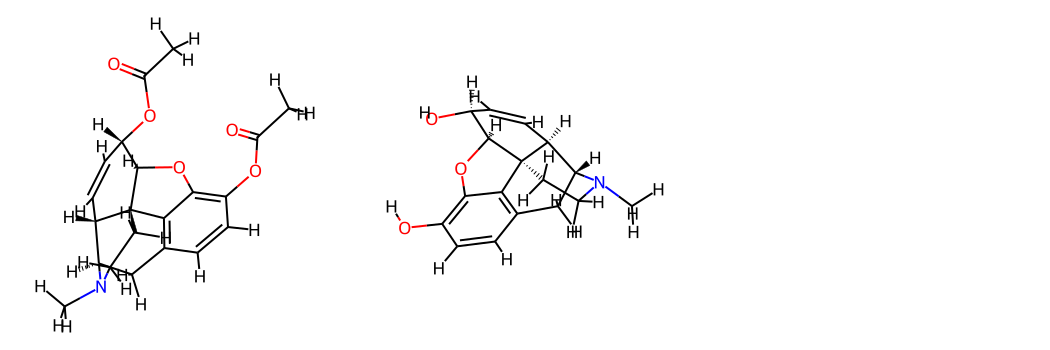

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [18]:
# Draw the 2D structures side by side
img = Draw.MolsToGridImage((mol2, morphine_H), subImgSize=(350,350), #molsPerRow=2
                           )
display(img)

#pymol
v.show()
v1.show()

In [19]:
def smi2conf(smiles):
    '''Convert SMILES to rdkit.Mol with 3D coordinates'''
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        mol = Chem.AddHs(mol)   #Agregar Hidrógenos
        AllChem.EmbedMolecule(mol) #Generar conformaciones
        AllChem.MMFFOptimizeMolecule(mol, maxIters=200) #Campo de fuerza
        return mol
    else:
        return None

In [20]:
smiles = Chem.MolToSmiles(morphine_H)
smiles

'[H]Oc1c([H])c([H])c2c3c1O[C@]1([H])[C@]34C([H])([H])C([H])([H])N(C([H])([H])[H])[C@]([H])(C2([H])[H])[C@]4([H])C([H])=C([H])[C@]1([H])O[H]'

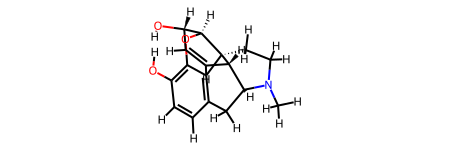

In [21]:
smi2conf(smiles)

In [22]:
def MolTo3DView(mol, size=(300, 300), style="stick", surface=False, opacity=0.5):
    assert style in ('line', 'stick', 'sphere', 'carton')
    mblock = Chem.MolToMolBlock(mol)
    viewer = py3Dmol.view(width=size[0], height=size[1])
    viewer.addModel(mblock, 'mol')
    viewer.setStyle({style:{}})
    if surface:
        viewer.addSurface(py3Dmol.SAS, {'opacity': opacity})
    viewer.zoomTo()
    return viewer

In [23]:
conf = smi2conf(Chem.MolToSmiles(morphine_H))
viewer = MolTo3DView(conf, size=(1200, 600), style='stick', surface=True, opacity=.4)#'stick', 'sphere')
viewer.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [24]:
conf = smi2conf(Chem.MolToSmiles(morphine_H))
viewer = MolTo3DView(conf, size=(1200, 600), style='sphere', surface=True, opacity=.4)#'stick', 'sphere')
viewer.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.